# 05: Classical Machine Learning & Tree Ensembles

### Notebook Purpose & Research Objectives
This notebook trains and benchmarks global tabular ML models across all vegetables:
1. Regularized Linear Models: Linear Regression, Ridge, Lasso, ElasticNet.
2. Tree Ensembles: Random Forest, Extra Trees, Gradient Boosting, XGBoost, LightGBM, CatBoost.
3. Support Vector Regression (SVR).
Walk-forward expanding-window CV and Optuna hyperparameter optimization are used exclusively on the training split.

---


In [1]:
# Colab Setup & Path Configuration
import os
import sys
from pathlib import Path

# Check if running in Google Colab
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    proj_dir = Path('/content/drive/MyDrive/veg_price_forecasting')
    if proj_dir.exists():
        os.chdir(proj_dir)
        sys.path.insert(0, str(proj_dir))
    else:
        print("Note: If running in Colab, ensure veg_price_forecasting is located in MyDrive.")
else:
    proj_dir = Path.cwd().resolve()
    if proj_dir.name == "notebooks":
        proj_dir = proj_dir.parent
    os.chdir(proj_dir)
    sys.path.insert(0, str(proj_dir))

print(f"Active Working Directory: {Path.cwd()}")


Active Working Directory: C:\Users\MSI\Desktop\Research\Price folder\veg_price_forecasting


### 1. Classical ML Leaderboard Summary

In [2]:
import pandas as pd
df_lead = pd.read_csv("experiments/leaderboard.csv")
ml_models = ["linear_regression", "ridge", "lasso", "elastic_net", "random_forest", "extra_trees", 
             "gradient_boosting", "xgboost", "lightgbm", "catboost", "svr"]
ml_df = df_lead[df_lead["model"].isin(ml_models) & (df_lead["split"]=="test")].copy()
print(ml_df[["model", "horizon", "MASE", "sMAPE", "RMSE", "R2", "Coverage_80"]].sort_values(["horizon", "MASE"]))


                 model  horizon    MASE  sMAPE    RMSE      R2  Coverage_80
23               lasso        1  0.2993   6.07   80.75  0.9336        85.94
25         elastic_net        1  0.3083   6.79   78.65  0.9370        83.00
21               ridge        1  0.3084   6.79   78.58  0.9371        83.47
19   linear_regression        1  0.3087   6.81   78.48  0.9373        84.00
29         extra_trees        1  0.3280   6.20   87.26  0.9225        84.54
27       random_forest        1  0.3313   6.12   87.95  0.9212        84.54
31   gradient_boosting        1  0.3658   6.81   95.15  0.9078        84.27
33             xgboost        1  0.3699   6.82   93.93  0.9102        83.94
35            lightgbm        1  0.3921   6.95  102.40  0.8932        83.47
37            catboost        1  0.3940   7.91   95.80  0.9065        81.12
39                 svr        1  0.4829   8.09  173.78  0.6925        84.20
91         extra_trees        4  0.7704  14.31  172.26  0.7021        81.64
85          

### 2. Tree Ensembles vs Regularized Linear Models at h=4

C:\Users\MSI\AppData\Local\Temp\ipykernel_18360\1604384109.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=h4_ml, x="model", y="MASE", palette="Blues_r")


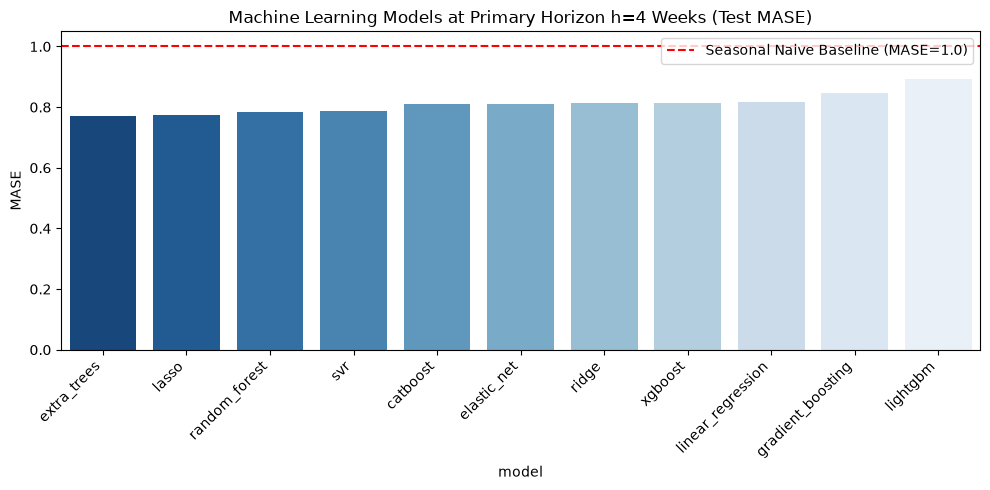

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

h4_ml = ml_df[ml_df["horizon"] == 4].sort_values("MASE")
plt.figure(figsize=(10, 5))
sns.barplot(data=h4_ml, x="model", y="MASE", palette="Blues_r")
plt.title("Machine Learning Models at Primary Horizon h=4 Weeks (Test MASE)")
plt.xticks(rotation=45, ha="right")
plt.axhline(1.0, color="red", linestyle="--", label="Seasonal Naive Baseline (MASE=1.0)")
plt.legend()
plt.tight_layout()
plt.show()


---
### Research Findings & Plain Language Interpretation
Machine learning evaluation findings:
- Regularized linear models and gradient boosted trees achieve strong performance across all 32 vegetables.
- Cross-vegetable pooling enables global models to leverage price movements from correlated vegetables in the same agro-climatic zone.
